# HYDRA-pCO2 Demos Generation

The rotating globe animation used in this notebook was adapted from code created by Arianna Olivelli (November 2025) for visualising gridded ocean products. 

The flat-map animation was developed with assistance from [ChatGPT conversation](https://chatgpt.com/share/6a8f928d-243c-83eb-bf36-f27c5d2aebd5).

In [ ]:
import os

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib import animation

print(animation.writers.list())
print("FFmpeg available:", animation.writers.is_available("ffmpeg"))

['pillow', 'ffmpeg', 'ffmpeg_file', 'html']
FFmpeg available: True


In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from utils.paths import (
    POSTERIOR_ZARR,
    DEMO_FIGURES_DIR,
    ensure_project_dirs,
    assert_exists,
    print_paths
)

ensure_project_dirs()

assert_exists(POSTERIOR_ZARR, "HYDRA-pCO2 posterior Zarr")

POSTERIOR_PATH = POSTERIOR_ZARR
DEMO_DIR = DEMO_FIGURES_DIR

STATIC_MMYY_PATH = DEMO_DIR / "HYDRA-pco2_Sep2021.png"    # hardcoded MMYY!
FLAT_GLOBE_PATH = DEMO_DIR / "HYDRA-pco2_flat_globe.mp4"
ROTATING_GLOBE_PATH = DEMO_DIR / "HYDRA-pco2_rotating_globe.gif"

print_paths(
    ("Posterior", POSTERIOR_ZARR),
    ("Demo path", DEMO_DIR)
)

### Load data

In [ ]:
posterior_ds = xr.open_zarr(POSTERIOR_PATH)
print(posterior_ds)
posterior = posterior_ds["pco2_total"]

<xarray.Dataset> Size: 224MB
Dimensions:           (time: 384, lat: 180, lon: 360)
Coordinates:
  * time              (time) datetime64[ns] 3kB 1993-01-01 ... 2024-12-01
    month_key         (time) int32 2kB dask.array<chunksize=(384,), meta=np.ndarray>
  * lat               (lat) float64 1kB -89.5 -88.5 -87.5 ... 87.5 88.5 89.5
  * lon               (lon) float64 3kB -179.5 -178.5 -177.5 ... 178.5 179.5
    member            int64 8B ...
Data variables:
    land_mask         (time, lat, lon) int8 25MB dask.array<chunksize=(96, 45, 180), meta=np.ndarray>
    pco2_total        (time, lat, lon) float32 100MB dask.array<chunksize=(48, 45, 90), meta=np.ndarray>
    pco2_uncertainty  (time, lat, lon) float32 100MB dask.array<chunksize=(48, 45, 90), meta=np.ndarray>
Attributes:
    holdout_fraction:               0.2
    holdout_seed:                   42
    member_ids_used:                [0, 1, 2, 3, 4]
    member_seeds:                   [42, 43, 44, 45, 46]
    method:                 

### Mean and standard deviation

In [ ]:
# Temporal mean and standard deviation across all 1993–2024 months
posterior_mean = posterior["pco2_total"].mean(dim="time")  # or posterior_ds?
posterior_std = posterior["pco2_uncertainty"].std(dim="time")

print("Mean range:", float(posterior_mean.min()), float(posterior_mean.max()))
print("STD range:", float(posterior_std.min()), float(posterior_std.max()))

Mean range: 177.06130981445312 599.1105346679688


/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: Runtime

STD range: 0.0 3.1809606552124023


/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


In [7]:
# Robust colour limits
mean_vmin = float(posterior_mean.quantile(0.02))
mean_vmax = float(posterior_mean.quantile(0.98))

std_vmax = float(posterior_std.quantile(0.98))

/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


/home/efs25/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


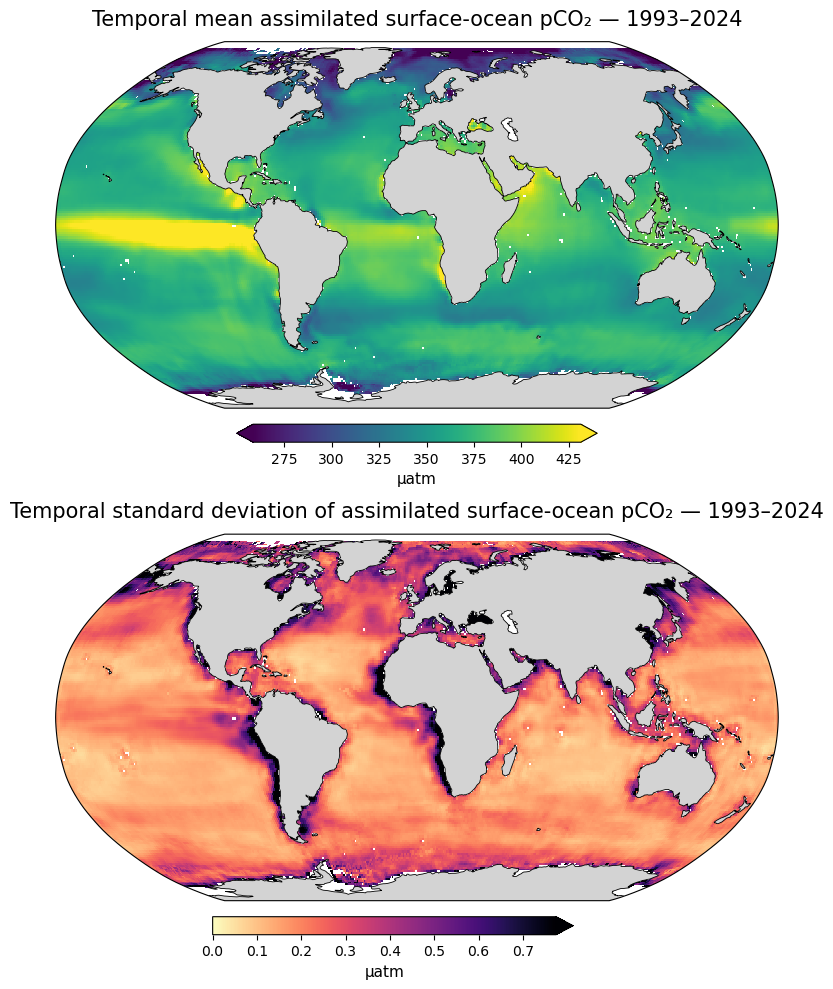

In [20]:
fig = plt.figure(figsize=(14, 10))

# ---------------------------------------------------------
# 1. Temporal mean
# ---------------------------------------------------------

ax1 = fig.add_subplot(
    2, 1, 1,
    projection=ccrs.Robinson()
)

ax1.set_global()

mesh1 = ax1.pcolormesh(
    posterior_mean.lon,
    posterior_mean.lat,
    posterior_mean,
    transform=ccrs.PlateCarree(),
    cmap="viridis",              # purple → green → yellow
    vmin=mean_vmin,
    vmax=mean_vmax,
    shading="auto",
    zorder=1,
)

ax1.add_feature(
    cfeature.LAND,
    facecolor="lightgray",
    edgecolor="none",
    zorder=2,
)

ax1.coastlines(
    linewidth=0.6,
    zorder=3,
)

cbar1 = fig.colorbar(
    mesh1,
    ax=ax1,
    orientation="horizontal",
    pad=0.04,
    fraction=0.045,
    # aspect=40,
    extend="both",
)

cbar1.set_label(
    "µatm",
    fontsize=11,
)

ax1.set_title(
    "Temporal mean assimilated surface-ocean pCO₂ — 1993–2024",
    fontsize=15,
    pad=12,
)


# ---------------------------------------------------------
# 2. Temporal standard deviation
# ---------------------------------------------------------

ax2 = fig.add_subplot(
    2, 1, 2,
    projection=ccrs.Robinson()
)

ax2.set_global()

mesh2 = ax2.pcolormesh(
    posterior_std.lon,
    posterior_std.lat,
    posterior_std,
    transform=ccrs.PlateCarree(),
    cmap="magma_r",                 # sequential uncertainty scale
    vmin=0,
    vmax=std_vmax,
    shading="auto",
    zorder=1,
)

ax2.add_feature(
    cfeature.LAND,
    facecolor="lightgray",
    edgecolor="none",
    zorder=2,
)

ax2.coastlines(
    linewidth=0.6,
    zorder=3,
)

cbar2 = fig.colorbar(
    mesh2,
    ax=ax2,
    orientation="horizontal",
    pad=0.04,
    fraction=0.045,
    # aspect=40,
    extend="max",                 # single triangle on high-value end
)

cbar2.set_label(
    "µatm",
    fontsize=11,
)

ax2.set_title(
    "Temporal standard deviation of assimilated surface-ocean pCO₂ — 1993–2024",
    fontsize=15,
    pad=12,
)

plt.tight_layout()

plt.show()
plt.close(fig)

## Demos

### 1. Static example of a month, year

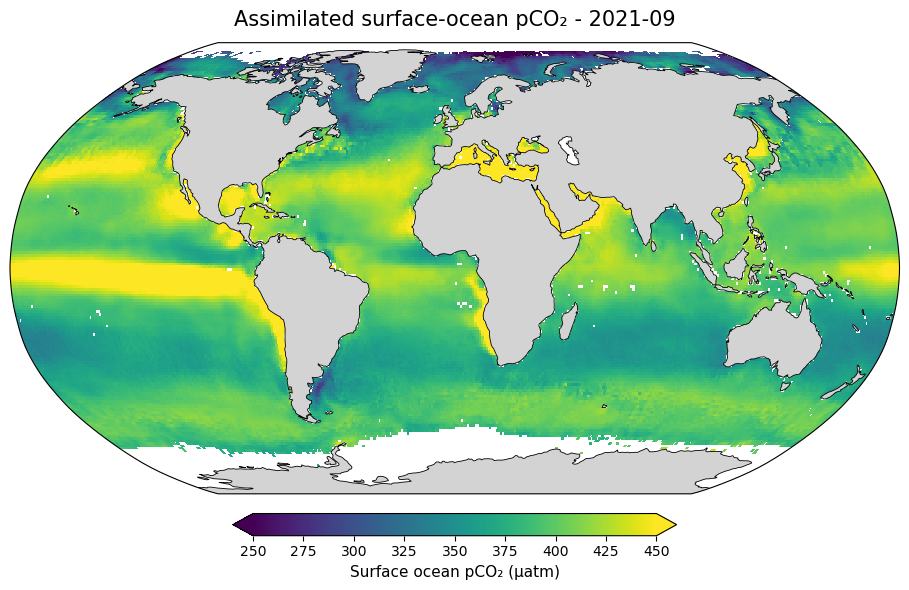

In [ ]:
def plot_product_example(
    posterior,
    time="2003-03-01",
    save_path=None,
    vmin=250,
    vmax=450,
):
    field = posterior.sel(time=time)

    fig = plt.figure(figsize=(12, 6))

    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()

    # Plot pCO2
    mesh = ax.pcolormesh(
        field.lon,
        field.lat,
        field,
        transform=ccrs.PlateCarree(),
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        shading="auto",
        zorder=1,
    )

    # Map features
    ax.add_feature(
        cfeature.LAND,
        facecolor="lightgray",
        edgecolor="none",
        zorder=2,
    )

    ax.coastlines(
        linewidth=0.6,
        zorder=3,
    )

    # Colourbar
    cbar = fig.colorbar(
        mesh,
        ax=ax,
        orientation="horizontal",
        pad=0.04,
        fraction=0.045,
        extend="both",
    )

    cbar.set_label(
        "Surface ocean pCO₂ (µatm)",
        fontsize=11,
    )

    # Title
    date = np.datetime_as_string(
        np.asarray(field.time.values),
        unit="M",
    )

    ax.set_title(
        rf"Assimilated surface-ocean pCO₂ - {date}",
        fontsize=15,
        pad=12,
    )

    plt.tight_layout()

    if save_path:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


plot_product_example(
    posterior=posterior,
    time="2021-09-01",
    save_path=STATIC_MMYY_PATH,
)

### 2. Flat globe animation of all months

In [ ]:
def save_pco2_animation(pco2, output_path, vmin=250, vmax=500, fps=12):
    """
    Create an MP4 animation of monthly assimilated surface-ocean pCO2

    Parameters
    ----------
    pco2 : xarray.DataArray
        Monthly pCO2 field with dimensions (time, lat, lon).
    output_path : str
        Path for the final MP4.
    vmin, vmax : float
        Fixed colourbar limits across all frames.
    fps : int
        Frames per second.
    """

    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    # Prepare data
    pco2 = pco2.transpose("time", "lat", "lon")

    times = pco2.time.values
    lats = pco2.lat.values
    lons = pco2.lon.values
    data = pco2.values

    # Figure

    fig = plt.figure(figsize=(12, 6))

    ax = plt.axes(projection=ccrs.Robinson())

    ax.set_global()
    ax.add_feature(
        cfeature.LAND,
        facecolor="lightgray",
        zorder=2,
    )
    ax.coastlines(
        linewidth=0.6,
        zorder=3,
    )

    # Longitude/latitude mesh
    lon2d, lat2d = np.meshgrid(lons, lats)

    # First frame
    mesh = ax.pcolormesh(
        lon2d,
        lat2d,
        data[0],
        transform=ccrs.PlateCarree(),
        shading="auto",
        vmin=vmin,
        vmax=vmax,
        cmap="viridis",
        zorder=1,
    )

    # Colourbar
    cbar = fig.colorbar(
        mesh,
        ax=ax,
        orientation="horizontal",
        pad=0.04,
        fraction=0.045,
        extend="both",
    )

    cbar.set_label("Surface ocean pCO₂ (µatm)")

    # Title
    title = ax.set_title(
        "",
        fontsize=16,
        pad=12,
    )

    # Animation update
    def update(frame):

        mesh.set_array(data[frame].ravel())

        date = np.datetime_as_string(
            times[frame],
            unit="M",
        )

        title.set_text(rf"Assimilated surface ocean pCO₂ - {date}")

        return mesh, title

    # Create animation
    ani = animation.FuncAnimation(
        fig,
        update,
        frames=len(times),
        interval=1000 / fps,
        blit=False,
    )

    # Save
    print(f"Saving animation to: {output_path}")

    ani.save(
        output_path,
        writer="ffmpeg",
        fps=fps,
        dpi=150,
    )

    plt.close(fig)

    print("Animation saved successfully.")

save_pco2_animation(
    posterior,
    output_path=FLAT_GLOBE_PATH,
    vmin=250,
    vmax=500,
    fps=8,
)

# 2m  to run

Saving animation to: /home/efs25/GitHub/irp-efs25/figures/demo/HYDRA-pco2_flat_globe.mp4
Animation saved successfully.


### 3. Rotating globe animation of all months

In [4]:
def save_rotating_globe_animation(
    pco2,
    output_path,
    vmin=250,
    vmax=450,
    fps=8,
    rot_step=1.5,
):
    """
    Create a rotating globe GIF of monthly assimilated surface-ocean pCO2.
    """

    pco2 = pco2.transpose("time", "lat", "lon")

    times = pco2.time.values
    lats = pco2.lat.values
    lons = pco2.lon.values
    data = pco2.values

    cmap = plt.cm.viridis.copy()
    cmap.set_bad("lightgray")

    # Open GIF writer so frames are written directly rather than
    # storing the entire animation in memory.
    with imageio.get_writer(
        output_path,
        mode="I",
        fps=fps,
        loop=0,
        subrectangles=True,
    ) as writer:

        for t_i, t in enumerate(times):

            field = data[t_i]

            # Three rotation frames per month
            # for f in range(3):

            #     angle = (t_i * 3 + f) * rot_step
            for f in range(2):

                angle = t_i * 4.5 + f * 2.25

                fig = plt.figure(
                    figsize=(8, 6),
                    dpi=60,
                )

                ax = fig.add_axes(
                    [0.05, 0.05, 0.80, 0.85],
                    projection=ccrs.NearsidePerspective(
                        central_longitude=angle,
                        central_latitude=10,
                        satellite_height=35785831,
                    ),
                )

                ax.set_global()

                mesh = ax.pcolormesh(
                    lons,
                    lats,
                    field,
                    transform=ccrs.PlateCarree(),
                    shading="auto",
                    cmap=cmap,
                    vmin=vmin,
                    vmax=vmax,
                )

                ax.add_feature(
                    cfeature.LAND,
                    facecolor="lightgray",
                    edgecolor="none",
                    zorder=3,
                )

                ax.coastlines(
                    linewidth=0.5,
                    zorder=4,
                )

                # Colourbar
                cax = fig.add_axes(
                    [0.87, 0.27, 0.025, 0.4]
                )

                cbar = fig.colorbar(
                    mesh,
                    cax=cax,
                    orientation="vertical",
                    extend="both",
                )

                cbar.set_label(
                    "pCO₂ (µatm)",
                    fontsize=9,
                )

                date = np.datetime_as_string(
                    t,
                    unit="M",
                )

                fig.suptitle(
                    f"HYDRA-pCO₂ ({date})",
                    fontsize=13,
                    fontweight="bold",
                    y=0.94,
                )

                # Render figure
                fig.canvas.draw()

                frame = np.asarray(
                    fig.canvas.buffer_rgba()
                )[:, :, :3]

                # Write immediately rather than storing in memory
                writer.append_data(frame)

                plt.close(fig)

    print(
        f"Saved rotating globe animation to: {output_path}"
    )


save_rotating_globe_animation(
    posterior,
    output_path=ROTATING_GLOBE_PATH,
    vmin=250,
    vmax=450,
    fps=8,
    rot_step=1.5,
)

Saved rotating globe animation to: /home/efs25/GitHub/irp-efs25/figures/demo/HYDRA-pco2_rotating_globe.gif
